# Personal Finance & Expense Analyzer
### Individual Data Analytics Project using Python, NumPy, Pandas, Matplotlib and Seaborn

**Project level:** Intermediate  
**Dataset:** 3,000+ synthetic transactions spanning 2025  
**Currency:** Indian Rupees (₹)

## Project overview
This notebook explores personal income and expenses, cleans common data-quality issues, calculates financial metrics, identifies spending patterns, and visualizes monthly trends.

> **Data privacy note:** The data is synthetic and does not represent real people or bank accounts. It is for learning and demonstration only.

## Objectives
1. Inspect and clean transaction data.
2. Use NumPy for numerical/statistical calculations.
3. Use Pandas for filtering, grouping, aggregation, pivot tables, and time-series analysis.
4. Visualize income, expenses, categories, payment modes, and savings trends.
5. Turn analysis into clear, evidence-based insights.

## Notebook workflow
**Generate/load → Inspect → Clean → Validate → Analyze → Visualize → Summarize**

## 1. Import libraries
We use:
- **NumPy** for numerical operations and statistics.
- **Pandas** for tabular data handling and analysis.
- **Matplotlib/Seaborn** for charts.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# Consistent visual defaults (no custom color palette required)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully.
Pandas version: 3.0.5
NumPy version: 2.4.2


## 2. Generate a reproducible synthetic dataset
This cell creates the dataset so the notebook can run independently. It contains a few intentional issues (missing values, inconsistent capitalization, a negative amount, and duplicate rows) that we will detect and handle in the cleaning section.

If you downloaded the companion `transactions.csv`, you can load it directly in the next section instead.

In [5]:
rng = np.random.default_rng(42)
n = 3000

categories = [
    "Food", "Housing", "Transport", "Shopping", "Healthcare",
    "Entertainment", "Education", "Utilities", "Salary", "Freelance", "Investment"
]
descriptions = {
    "Food": ["Groceries", "Restaurant", "Cafe", "Food Delivery"],
    "Housing": ["House Rent", "Maintenance", "Furniture"],
    "Transport": ["Fuel", "Bus", "Train", "Cab"],
    "Shopping": ["Clothing", "Electronics", "Online Shopping"],
    "Healthcare": ["Medicine", "Doctor", "Medical Test"],
    "Entertainment": ["Movie", "Subscription", "Gaming"],
    "Education": ["Course Fee", "Books", "Online Course"],
    "Utilities": ["Electricity", "Internet", "Mobile Bill"],
    "Salary": ["Monthly Salary", "Bonus"],
    "Freelance": ["Freelance Payment", "Consulting"],
    "Investment": ["Dividend", "Investment Return"]
}

start_epoch = pd.Timestamp("2025-01-01").value // 10**9
end_epoch = pd.Timestamp("2026-01-01").value // 10**9
dates = pd.to_datetime(
    rng.integers(start_epoch, end_epoch, size=n), unit="s"
).normalize()

category = rng.choice(
    categories,
    size=n,
    p=[0.20, 0.08, 0.12, 0.13, 0.06, 0.08, 0.05, 0.08, 0.08, 0.07, 0.05]
)
income_categories = ["Salary", "Freelance", "Investment"]
transaction_type = np.where(np.isin(category, income_categories), "Income", "Expense")

amounts = []
for cat in category:
    if cat == "Salary":
        amounts.append(rng.integers(25_000, 65_001))
    elif cat == "Freelance":
        amounts.append(rng.integers(1_000, 20_001))
    elif cat == "Investment":
        amounts.append(rng.integers(500, 10_001))
    elif cat == "Housing":
        amounts.append(rng.integers(5_000, 18_001))
    else:
        amounts.append(rng.integers(100, 5_001))

raw_df = pd.DataFrame({
    "Transaction_ID": [f"TXN{i:05d}" for i in range(1, n + 1)],
    "Date": dates,
    "Description": [rng.choice(descriptions[cat]) for cat in category],
    "Category": category,
    "Type": transaction_type,
    "Amount": amounts,
    "Payment_Mode": rng.choice(
        ["UPI", "Cash", "Debit Card", "Credit Card", "Bank Transfer"], size=n
    ),
    "Account": rng.choice(["Savings", "Current", "Credit"], size=n, p=[0.65, 0.15, 0.20]),
    "City": rng.choice(["Pune", "Mumbai", "Sangli", "Nashik", "Nagpur"], size=n)
})

# Intentional data-quality issues for practice
raw_df.loc[10, "Description"] = None
raw_df.loc[25, "Category"] = None
raw_df.loc[40, "Amount"] = np.nan
raw_df.loc[50, "Payment_Mode"] = "upi"
raw_df.loc[60, "Amount"] = -500

# Add two duplicated records
raw_df = pd.concat([raw_df, raw_df.iloc[[100, 200]]], ignore_index=True)

# Save a copy in the notebook working directory
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
raw_df.to_csv(data_dir / "transactions.csv", index=False)

print(f"Generated {len(raw_df):,} rows and {raw_df.shape[1]} columns.")
print("Saved a copy to:", data_dir / "transactions.csv")
display(raw_df.head())

Generated 3,002 rows and 9 columns.
Saved a copy to: data\transactions.csv


,Transaction_ID,Date,Description,Category,Type,Amount,Payment_Mode,Account,City
0,TXN00001,2025-02-02,Dividend,Investment,Income,"6,883.00",Debit Card,Savings,Nagpur
1,TXN00002,2025-10-10,Fuel,Transport,Expense,"3,399.00",Debit Card,Savings,Nashik
2,TXN00003,2025-08-27,Clothing,Shopping,Expense,"2,330.00",Credit Card,Savings,Mumbai
3,TXN00004,2025-06-10,Bonus,Salary,Income,"55,862.00",Debit Card,Savings,Nagpur
4,TXN00005,2025-06-08,Electronics,Shopping,Expense,"3,129.00",UPI,Current,Pune


## 3. Load and inspect the data
The raw dataset is retained in `raw_df`. We will use `df` as the working copy for cleaning.

`head`, `shape`, `info`, `describe`, and missing-value counts answer different questions about the structure and quality of the dataset.

In [6]:
# Load the generated CSV to practise real file loading
df = pd.read_csv(data_dir / "transactions.csv")

print("First five rows:")
display(df.head())

print("Dataset shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nNumerical summary:")
display(df.describe())

print("\nMissing values per column:")
display(df.isna().sum().rename("missing_count").to_frame())

print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicate transaction IDs:", df["Transaction_ID"].duplicated().sum())

First five rows:


,Transaction_ID,Date,Description,Category,Type,Amount,Payment_Mode,Account,City
0,TXN00001,2025-02-02,Dividend,Investment,Income,"6,883.00",Debit Card,Savings,Nagpur
1,TXN00002,2025-10-10,Fuel,Transport,Expense,"3,399.00",Debit Card,Savings,Nashik
2,TXN00003,2025-08-27,Clothing,Shopping,Expense,"2,330.00",Credit Card,Savings,Mumbai
3,TXN00004,2025-06-10,Bonus,Salary,Income,"55,862.00",Debit Card,Savings,Nagpur
4,TXN00005,2025-06-08,Electronics,Shopping,Expense,"3,129.00",UPI,Current,Pune


Dataset shape (rows, columns): (3002, 9)

Column names:
['Transaction_ID', 'Date', 'Description', 'Category', 'Type', 'Amount', 'Payment_Mode', 'Account', 'City']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Transaction_ID  3002 non-null   str    
 1   Date            3002 non-null   str    
 2   Description     3001 non-null   str    
 3   Category        3001 non-null   str    
 4   Type            3002 non-null   str    
 5   Amount          3001 non-null   float64
 6   Payment_Mode    3002 non-null   str    
 7   Account         3002 non-null   str    
 8   City            3002 non-null   str    
dtypes: float64(1), str(8)
memory usage: 395.2 KB

Numerical summary:


,Amount
count,"3,001.00"
mean,"7,490.99"
std,"12,373.08"
min,-500.00
25%,"1,781.00"
50%,"3,350.00"
75%,"5,089.00"
max,"64,900.00"



Missing values per column:


,missing_count
Transaction_ID,0
Date,0
Description,1
Category,1
Type,0
Amount,1
Payment_Mode,0
Account,0
City,0



Fully duplicated rows: 2
Duplicate transaction IDs: 2


## 4. Data-quality assessment
Before cleaning, we explicitly check the key assumptions:
- Dates should be valid dates.
- Amounts should be numeric and positive in this dataset's convention.
- Transaction IDs should be unique.
- Type should be either `Income` or `Expense`.
- Payment modes should use consistent capitalization.

**Cleaning decisions:** remove duplicate transaction IDs; parse dates; standardize text; label missing descriptions/categories; impute a missing amount using the median for its transaction type; and correct the single known negative amount using its absolute value. In a real banking dataset, we would investigate negative amounts instead of automatically changing them.

In [7]:
quality_report = pd.DataFrame({
    "Issue": [
        "Missing dates",
        "Missing descriptions",
        "Missing categories",
        "Missing amounts",
        "Negative amounts",
        "Duplicate transaction IDs",
        "Non-standard payment-mode capitalization"
    ],
    "Count": [
        df["Date"].isna().sum(),
        df["Description"].isna().sum(),
        df["Category"].isna().sum(),
        df["Amount"].isna().sum(),
        (pd.to_numeric(df["Amount"], errors="coerce") < 0).sum(),
        df["Transaction_ID"].duplicated().sum(),
        (df["Payment_Mode"].astype(str) != df["Payment_Mode"].astype(str).str.title()).sum()
    ]
})
display(quality_report)

,Issue,Count
0,Missing dates,0
1,Missing descriptions,1
2,Missing categories,1
3,Missing amounts,1
4,Negative amounts,1
5,Duplicate transaction IDs,2
6,Non-standard payment-mode capitalization,584


## 5. Clean the dataset
We apply each transformation in a visible, auditable sequence. This is preferable to changing data without documenting the reason.

In [8]:
clean_df = df.copy()

# 1) Remove repeated transaction IDs, keeping the first record
clean_df = clean_df.drop_duplicates(subset="Transaction_ID", keep="first").copy()

# 2) Convert fields to appropriate data types
clean_df["Date"] = pd.to_datetime(clean_df["Date"], errors="coerce")
clean_df["Amount"] = pd.to_numeric(clean_df["Amount"], errors="coerce")

# 3) Standardize text fields
text_columns = ["Description", "Category", "Type", "Payment_Mode", "Account", "City"]
for col in text_columns:
    clean_df[col] = clean_df[col].astype("string").str.strip()

clean_df["Payment_Mode"] = clean_df["Payment_Mode"].str.title()
clean_df["Type"] = clean_df["Type"].str.title()
clean_df["Category"] = clean_df["Category"].str.title()

# 4) Replace missing labels
clean_df["Description"] = clean_df["Description"].fillna("Unknown Description")
clean_df["Category"] = clean_df["Category"].fillna("Uncategorized")
clean_df["Payment_Mode"] = clean_df["Payment_Mode"].fillna("Unknown")
clean_df["Account"] = clean_df["Account"].fillna("Unknown")
clean_df["City"] = clean_df["City"].fillna("Unknown")

# 5) Do not invent financial amounts: exclude rows with missing or negative amounts.
invalid_date_rows = int(clean_df["Date"].isna().sum())
invalid_amount_rows = int(
    (clean_df["Amount"].isna() | clean_df["Amount"].lt(0)).sum()
)
clean_df = clean_df.dropna(subset=["Date", "Amount"])
clean_df = clean_df[clean_df["Amount"] >= 0].copy()

# 6) Keep rows with valid transaction types
clean_df = clean_df[clean_df["Type"].isin(["Income", "Expense"])].copy()

# 7) Add date features used in analysis
clean_df["Year"] = clean_df["Date"].dt.year
clean_df["Month"] = clean_df["Date"].dt.month
clean_df["Month_Name"] = clean_df["Date"].dt.strftime("%b")
clean_df["Year_Month"] = clean_df["Date"].dt.to_period("M").astype(str)

clean_df["Amount"] = clean_df["Amount"].astype(float)

print("Raw rows:", len(df))
print("Clean rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))
print("Rows with invalid dates:", invalid_date_rows)
print("Rows with missing or negative amounts:", invalid_amount_rows)
print("\nRemaining missing values:")
display(clean_df.isna().sum().to_frame("missing_count"))
print("\nRemaining duplicate transaction IDs:", clean_df["Transaction_ID"].duplicated().sum())
display(clean_df.head())

Raw rows: 3002
Clean rows: 3000
Rows removed: 2

Remaining missing values:


,missing_count
Transaction_ID,0
Date,0
Description,0
Category,0
Type,0
Amount,0
Payment_Mode,0
Account,0
City,0
Year,0



Remaining duplicate transaction IDs: 0


,Transaction_ID,Date,Description,Category,Type,Amount,Payment_Mode,Account,City,Year,Month,Month_Name,Year_Month
0,TXN00001,2025-02-02,Dividend,Investment,Income,"6,883.00",Debit Card,Savings,Nagpur,2025,2,Feb,2025-02
1,TXN00002,2025-10-10,Fuel,Transport,Expense,"3,399.00",Debit Card,Savings,Nashik,2025,10,Oct,2025-10
2,TXN00003,2025-08-27,Clothing,Shopping,Expense,"2,330.00",Credit Card,Savings,Mumbai,2025,8,Aug,2025-08
3,TXN00004,2025-06-10,Bonus,Salary,Income,"55,862.00",Debit Card,Savings,Nagpur,2025,6,Jun,2025-06
4,TXN00005,2025-06-08,Electronics,Shopping,Expense,"3,129.00",Upi,Current,Pune,2025,6,Jun,2025-06


## 6. Validate the cleaned data
Validation confirms whether the cleaned data meets our rules. A clean dataset is not automatically a correct dataset; the rules should match the meaning of the data.

In [9]:
assert clean_df["Transaction_ID"].is_unique, "Transaction IDs must be unique."
assert clean_df["Amount"].notna().all(), "Amounts should not be missing."
assert (clean_df["Amount"] >= 0).all(), "Amounts should be non-negative."
assert clean_df["Type"].isin(["Income", "Expense"]).all(), "Unexpected transaction type."
assert pd.api.types.is_datetime64_any_dtype(clean_df["Date"]), "Date must be datetime."

print("All validation checks passed.")
print(f"Clean dataset contains {len(clean_df):,} transactions.")

All validation checks passed.
Clean dataset contains 3,000 transactions.


## 7. Create reusable financial metrics with Pandas
For this project, each transaction amount is stored as a positive number, while `Type` determines whether it is income or expense.
- **Net cash flow** = income − expenses
- **Savings rate** = net cash flow ÷ income × 100 (only meaningful when income is positive)

These are simplified educational metrics, not formal accounting statements.

In [10]:
income = clean_df.loc[clean_df["Type"] == "Income", "Amount"].sum()
expenses = clean_df.loc[clean_df["Type"] == "Expense", "Amount"].sum()
net_cash_flow = income - expenses
savings_rate = (net_cash_flow / income * 100) if income > 0 else np.nan

summary = pd.DataFrame({
    "Metric": ["Total Income", "Total Expenses", "Net Cash Flow", "Savings Rate", "Transactions"],
    "Value": [income, expenses, net_cash_flow, savings_rate, len(clean_df)]
})
display(summary)
print(f"Total income: ₹{income:,.2f}")
print(f"Total expenses: ₹{expenses:,.2f}")
print(f"Net cash flow: ₹{net_cash_flow:,.2f}")
print(f"Savings rate: {savings_rate:.2f}%" if pd.notna(savings_rate) else "Savings rate unavailable")

,Metric,Value
0,Total Income,"14,025,073.00"
1,Total Expenses,"8,452,383.00"
2,Net Cash Flow,"5,572,690.00"
3,Savings Rate,39.73
4,Transactions,"3,000.00"


Total income: ₹14,025,073.00
Total expenses: ₹8,452,383.00
Net cash flow: ₹5,572,690.00
Savings rate: 39.73%


## 8. NumPy statistics
Here we use NumPy for distribution summaries and percentiles. These statistics describe transaction amounts, not the user's overall wealth.

In [11]:
expense_amounts = clean_df.loc[clean_df["Type"] == "Expense", "Amount"].to_numpy(dtype=float)
income_amounts = clean_df.loc[clean_df["Type"] == "Income", "Amount"].to_numpy(dtype=float)

numpy_stats = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Standard deviation", "Minimum", "75th percentile", "95th percentile", "Maximum"],
    "Expense amounts": [
        np.mean(expense_amounts), np.median(expense_amounts),
        np.std(expense_amounts, ddof=1), np.min(expense_amounts),
        np.percentile(expense_amounts, 75), np.percentile(expense_amounts, 95),
        np.max(expense_amounts)
    ],
    "Income amounts": [
        np.mean(income_amounts), np.median(income_amounts),
        np.std(income_amounts, ddof=1), np.min(income_amounts),
        np.percentile(income_amounts, 75), np.percentile(income_amounts, 95),
        np.max(income_amounts)
    ]
})
display(numpy_stats)

,Statistic,Expense amounts,Income amounts
0,Mean,"3,514.50","23,571.55"
1,Median,"2,871.00","14,267.00"
2,Standard deviation,"3,296.76","20,151.78"
3,Minimum,101.00,589.00
4,75th percentile,"4,208.00","41,514.50"
5,95th percentile,"11,908.80","59,141.00"
6,Maximum,"17,958.00","64,900.00"


## 9. Category analysis using `groupby`
We calculate transaction count, total amount, average transaction amount, and share of total expense for each category. Only expense transactions are included in the spending-category ranking.

In [12]:
expenses_df = clean_df[clean_df["Type"] == "Expense"].copy()
category_analysis = (
    expenses_df.groupby("Category", as_index=False)
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Expense=("Amount", "sum"),
        Average_Expense=("Amount", "mean"),
        Median_Expense=("Amount", "median")
    )
    .sort_values("Total_Expense", ascending=False)
)
category_analysis["Expense_Share_Pct"] = (
    category_analysis["Total_Expense"] / category_analysis["Total_Expense"].sum() * 100
)
display(category_analysis.round(2))

,Category,Transaction_Count,Total_Expense,Average_Expense,Median_Expense,Expense_Share_Pct
4,Housing,260,"2,967,866.00","11,414.87","11,136.50",35.11
2,Food,611,"1,571,403.00","2,571.85","2,672.00",18.59
5,Shopping,407,"1,031,050.00","2,533.29","2,449.00",12.20
6,Transport,338,"890,534.00","2,634.72","2,638.50",10.54
8,Utilities,241,"607,865.00","2,522.26","2,513.00",7.19
1,Entertainment,224,"560,361.00","2,501.61","2,559.00",6.63
3,Healthcare,180,"467,605.00","2,597.81","2,588.00",5.53
0,Education,143,"350,823.00","2,453.31","2,316.00",4.15
7,Uncategorized,1,"4,876.00","4,876.00","4,876.00",0.06


## 10. Monthly income, expenses, and net cash flow
We aggregate transactions by month and type. Using a monthly period ensures the chart is chronologically sorted.

In [13]:
monthly = (
    clean_df.pivot_table(
        index="Year_Month",
        columns="Type",
        values="Amount",
        aggfunc="sum",
        fill_value=0
    )
    .sort_index()
)

for col in ["Income", "Expense"]:
    if col not in monthly.columns:
        monthly[col] = 0.0

monthly["Net_Cash_Flow"] = monthly["Income"] - monthly["Expense"]
monthly = monthly.reset_index()
display(monthly.round(2))

Type,Year_Month,Expense,Income,Net_Cash_Flow
0,2025-01,"639,091.00","885,513.00","246,422.00"
1,2025-02,"807,785.00","1,420,619.00","612,834.00"
2,2025-03,"728,756.00","962,327.00","233,571.00"
3,2025-04,"727,808.00","792,041.00","64,233.00"
4,2025-05,"592,930.00","1,370,163.00","777,233.00"
5,2025-06,"762,800.00","1,326,622.00","563,822.00"
6,2025-07,"666,108.00","1,298,018.00","631,910.00"
7,2025-08,"841,601.00","1,161,517.00","319,916.00"
8,2025-09,"561,410.00","1,084,820.00","523,410.00"
9,2025-10,"674,829.00","1,783,487.00","1,108,658.00"


## 11. Payment-mode and city analysis
These summaries can help answer which payment methods and cities have the highest transaction activity. Because the data is synthetic, treat patterns as demonstration results rather than real-world findings.

In [14]:
payment_analysis = (
    clean_df.groupby("Payment_Mode")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Amount=("Amount", "sum"),
        Average_Amount=("Amount", "mean")
    )
    .sort_values("Transaction_Count", ascending=False)
)
city_analysis = (
    clean_df.groupby("City")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Amount=("Amount", "sum")
    )
    .sort_values("Total_Amount", ascending=False)
)

print("Payment mode analysis")
display(payment_analysis.round(2))
print("City analysis")
display(city_analysis.round(2))

Payment mode analysis


,Transaction_Count,Total_Amount,Average_Amount
Payment_Mode,,,
Credit Card,630,"4,577,436.00","7,265.77"
Cash,613,"4,377,235.00","7,140.68"
Debit Card,588,"4,480,034.00","7,619.11"
Bank Transfer,585,"4,552,644.00","7,782.30"
Upi,584,"4,490,107.00","7,688.54"


City analysis


,Transaction_Count,Total_Amount
City,,
Pune,633,"4,646,226.00"
Nagpur,568,"4,624,750.00"
Sangli,593,"4,606,494.00"
Nashik,613,"4,501,517.00"
Mumbai,593,"4,098,469.00"


## 12. Top transactions and outlier review
The largest transactions are useful to inspect, but a large amount is not automatically an error. Outliers should be reviewed in context.

In [15]:
print("Top 10 transactions by amount")
display(
    clean_df.nlargest(10, "Amount")[
        ["Transaction_ID", "Date", "Description", "Category", "Type", "Amount", "Payment_Mode", "City"]
    ]
)

expense_q1 = expenses_df["Amount"].quantile(0.25)
expense_q3 = expenses_df["Amount"].quantile(0.75)
iqr = expense_q3 - expense_q1
upper_fence = expense_q3 + 1.5 * iqr
expense_outliers = expenses_df[expenses_df["Amount"] > upper_fence]

print(f"Expense outlier review threshold (IQR rule): ₹{upper_fence:,.2f}")
print(f"Number of expense transactions above threshold: {len(expense_outliers)}")
display(expense_outliers.nlargest(10, "Amount")[["Date", "Description", "Category", "Amount"]])

Top 10 transactions by amount


,Transaction_ID,Date,Description,Category,Type,Amount,Payment_Mode,City
121,TXN00122,2025-09-01,Bonus,Salary,Income,"64,900.00",Upi,Pune
2447,TXN02448,2025-10-12,Bonus,Salary,Income,"64,884.00",Credit Card,Nagpur
368,TXN00369,2025-01-09,Monthly Salary,Salary,Income,"64,877.00",Upi,Nashik
2700,TXN02701,2025-10-18,Monthly Salary,Salary,Income,"64,795.00",Cash,Nashik
1589,TXN01590,2025-09-26,Monthly Salary,Salary,Income,"64,549.00",Credit Card,Mumbai
1148,TXN01149,2025-11-07,Monthly Salary,Salary,Income,"64,373.00",Bank Transfer,Nashik
875,TXN00876,2025-07-04,Bonus,Salary,Income,"64,318.00",Upi,Nagpur
37,TXN00038,2025-10-30,Bonus,Salary,Income,"64,213.00",Credit Card,Nagpur
401,TXN00402,2025-10-11,Monthly Salary,Salary,Income,"64,209.00",Upi,Mumbai
218,TXN00219,2025-06-13,Bonus,Salary,Income,"63,931.00",Bank Transfer,Pune


Expense outlier review threshold (IQR rule): ₹8,235.50
Number of expense transactions above threshold: 195


,Date,Description,Category,Amount
2434,2025-07-25,Furniture,Housing,"17,958.00"
2152,2025-07-18,House Rent,Housing,"17,769.00"
2545,2025-10-18,Furniture,Housing,"17,762.00"
166,2025-04-28,House Rent,Housing,"17,757.00"
2235,2025-04-02,Furniture,Housing,"17,616.00"
2927,2025-03-09,Maintenance,Housing,"17,603.00"
53,2025-06-20,Furniture,Housing,"17,568.00"
445,2025-08-30,House Rent,Housing,"17,565.00"
1888,2025-06-14,Maintenance,Housing,"17,487.00"
1617,2025-02-14,Furniture,Housing,"17,449.00"


## 13. Visualizations
Each chart answers a specific question. Titles and axis labels make charts easier to understand in a presentation.

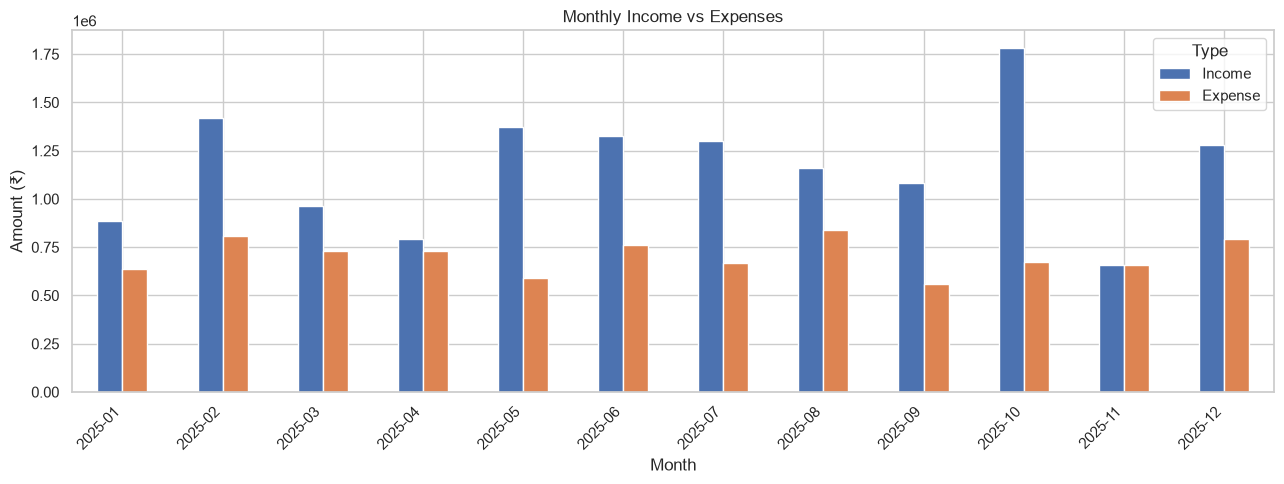

In [16]:
# 13.1 Monthly income vs expenses
plot_monthly = monthly.set_index("Year_Month")
ax = plot_monthly[["Income", "Expense"]].plot(kind="bar", figsize=(13, 5))
ax.set_title("Monthly Income vs Expenses")
ax.set_xlabel("Month")
ax.set_ylabel("Amount (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

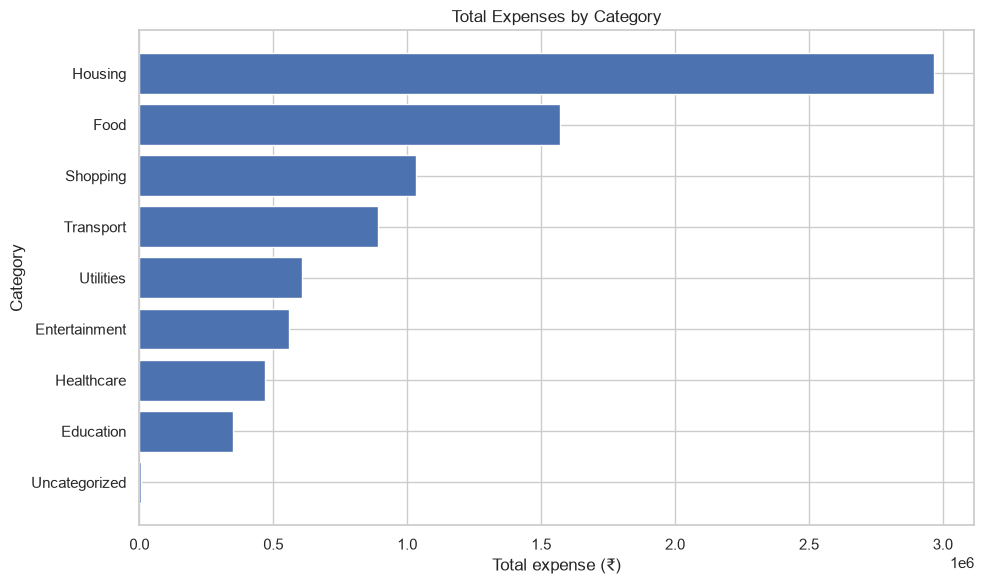

In [17]:
# 13.2 Total expense by category
category_plot = category_analysis.sort_values("Total_Expense", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(category_plot["Category"], category_plot["Total_Expense"])
plt.title("Total Expenses by Category")
plt.xlabel("Total expense (₹)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

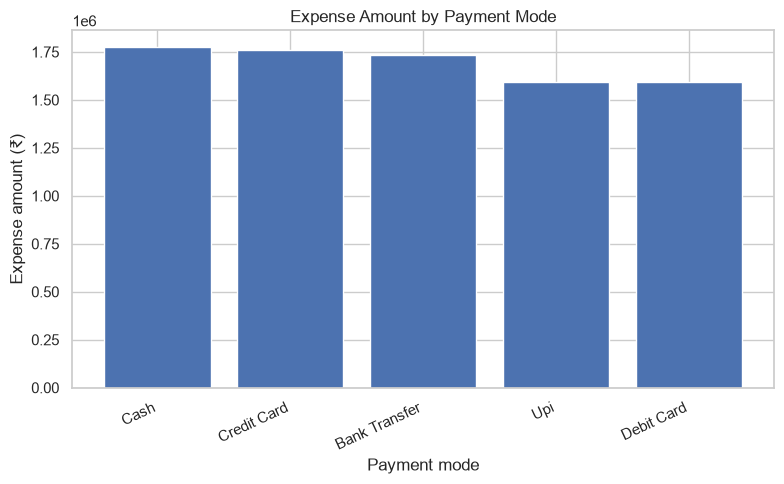

In [18]:
# 13.3 Expense distribution by payment mode
payment_expenses = expenses_df.groupby("Payment_Mode")["Amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
plt.bar(payment_expenses.index, payment_expenses.values)
plt.title("Expense Amount by Payment Mode")
plt.xlabel("Payment mode")
plt.ylabel("Expense amount (₹)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

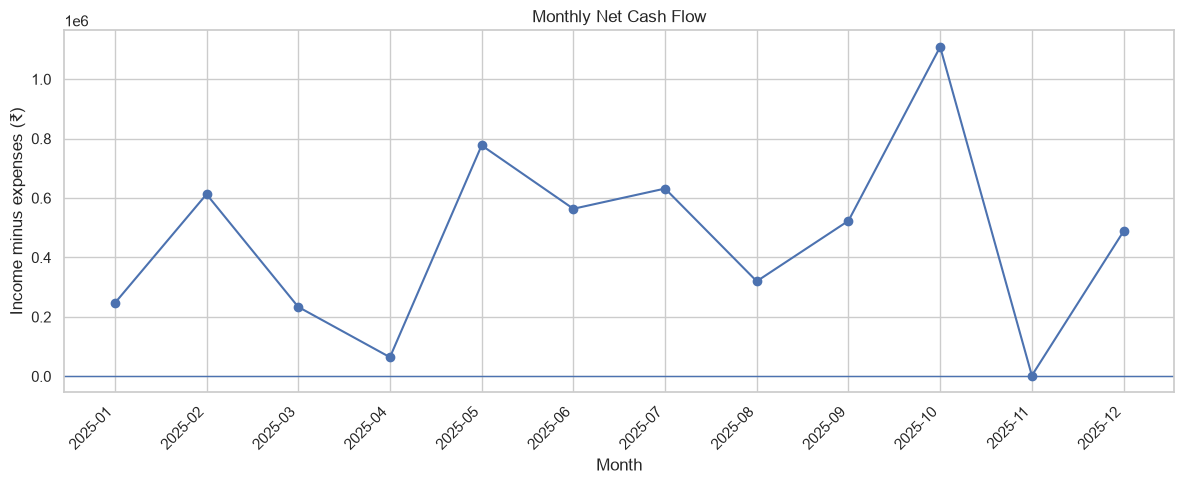

In [19]:
# 13.4 Monthly net cash flow
plt.figure(figsize=(12, 5))
plt.plot(monthly["Year_Month"], monthly["Net_Cash_Flow"], marker="o")
plt.axhline(0, linewidth=1)
plt.title("Monthly Net Cash Flow")
plt.xlabel("Month")
plt.ylabel("Income minus expenses (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

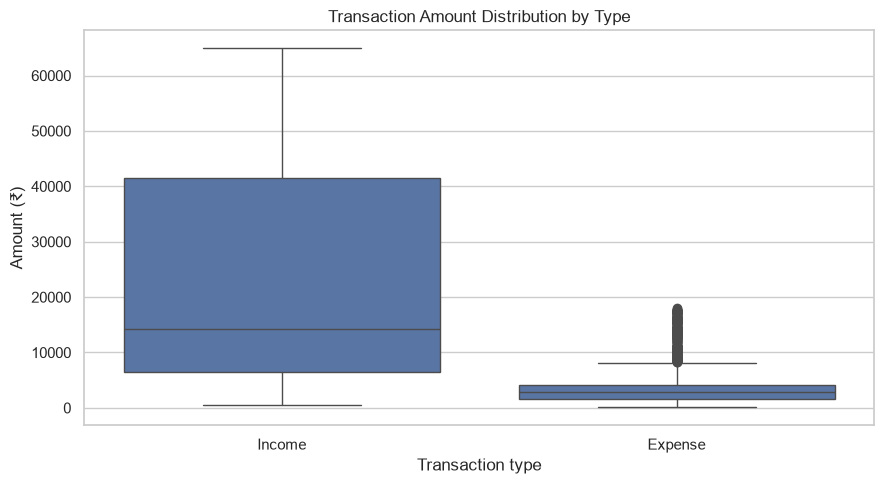

In [20]:
# 13.5 Distribution of transaction amounts by type
plt.figure(figsize=(9, 5))
sns.boxplot(data=clean_df, x="Type", y="Amount")
plt.title("Transaction Amount Distribution by Type")
plt.xlabel("Transaction type")
plt.ylabel("Amount (₹)")
plt.tight_layout()
plt.show()

## 14. Automatically summarize key findings
The code below generates observations from the computed tables rather than hard-coding a result. Review the findings and explain what they mean in your own words.

In [21]:
top_category = category_analysis.iloc[0]
top_payment = payment_analysis.index[0]
highest_expense_month = monthly.loc[monthly["Expense"].idxmax()]
best_cashflow_month = monthly.loc[monthly["Net_Cash_Flow"].idxmax()]
expense_mean = np.mean(expense_amounts)
expense_median = np.median(expense_amounts)

print("PROJECT INSIGHTS")
print("-" * 50)
print(f"Total income: ₹{income:,.2f}")
print(f"Total expenses: ₹{expenses:,.2f}")
print(f"Net cash flow: ₹{net_cash_flow:,.2f}")
print(f"Savings rate: {savings_rate:.2f}%" if pd.notna(savings_rate) else "Savings rate: unavailable")
print(f"Highest expense category: {top_category['Category']} (₹{top_category['Total_Expense']:,.2f})")
print(f"Payment mode with most transactions: {top_payment}")
print(f"Month with highest expenses: {highest_expense_month['Year_Month']} (₹{highest_expense_month['Expense']:,.2f})")
print(f"Month with highest net cash flow: {best_cashflow_month['Year_Month']} (₹{best_cashflow_month['Net_Cash_Flow']:,.2f})")
print(f"Mean expense transaction: ₹{expense_mean:,.2f}")
print(f"Median expense transaction: ₹{expense_median:,.2f}")

print("\nInterpretation reminder: these findings describe the generated synthetic dataset only.")

PROJECT INSIGHTS
--------------------------------------------------
Total income: ₹14,025,073.00
Total expenses: ₹8,452,383.00
Net cash flow: ₹5,572,690.00
Savings rate: 39.73%
Highest expense category: Housing (₹2,967,866.00)
Payment mode with most transactions: Credit Card
Month with highest expenses: 2025-08 (₹841,601.00)
Month with highest net cash flow: 2025-10 (₹1,108,658.00)
Mean expense transaction: ₹3,514.50
Median expense transaction: ₹2,871.00

Interpretation reminder: these findings describe the generated synthetic dataset only.


## 15. Export cleaned data and analysis tables
This creates output files that can be used later in a report or Streamlit dashboard. Files are written to an `output` folder relative to the notebook's current working directory.

In [23]:
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

clean_df.to_csv(output_dir / "cleaned_transactions.csv", index=False)
category_analysis.to_csv(output_dir / "category_analysis.csv", index=False)
monthly.to_csv(output_dir / "monthly_summary.csv", index=False)
payment_analysis.to_csv(output_dir / "payment_mode_analysis.csv")

print("Exported files:")
for file in sorted(output_dir.glob("*.csv")):
    print("-", file)

Exported files:
- output\category_analysis.csv
- output\cleaned_transactions.csv
- output\monthly_summary.csv
- output\payment_mode_analysis.csv


## 16. Project limitations and future improvements

### Limitations
- The dataset is synthetic and does not prove anything about real household spending.
- The cleaning rules are designed for this exercise. Real bank data may use negative values for refunds or reversals.
- A positive net cash flow in this notebook is not the same as a complete accounting or investment assessment.
- No currency conversion, recurring-payment detection, or budget-vs-actual analysis is included.

### Future improvements
1. Add a monthly budget and alert when spending exceeds the budget.
2. Add filters for date range, city, category, and payment mode.
3. Build a Streamlit dashboard with KPI cards and interactive charts.
4. Allow the user to upload their own CSV after validating its schema.
5. Add recurring expense detection and month-over-month percentage change.
6. Add automated tests for the data-cleaning functions.

## 17. Conclusion
This project demonstrates an end-to-end data-analysis workflow: creating data, inspecting data quality, cleaning and validating records, calculating metrics with NumPy, aggregating data with Pandas, visualizing patterns, and exporting analysis results. It provides a solid foundation for a portfolio project and can later be extended into an interactive Streamlit application.

### Viva preparation
Be ready to explain:
- Why we used NumPy and Pandas together.
- The difference between `loc` and `iloc`.
- What `groupby()` and `pivot_table()` do.
- Why missing values and duplicate IDs need to be handled.
- Why the mean and median can tell different stories.
- Why synthetic-data findings should not be treated as real financial advice.

In [ ]:
%pip install pdfplumber